# Microsoft commercial marketplace: free trials, free plans, conversion and revenue

**Ahmad Hassan** | AI Engineer · Client project (the data is private and not included in this repository)

A marketplace client sent several extracts of Microsoft commercial marketplace billing over 2020 to 2024 and asked a
series of questions across five deliveries. This notebook brings all of them into one analysis:

1. **Products with free trials:** how revenue grew, where it comes from (service, sales channel, billing action,
   MACC enrolment, plans), which products, publishers and customers dominate, what gets refunded, and whether ratings
   relate to revenue.
2. **Products with free plans:** how often a customer who starts free goes on to pay, and whether also offering a
   free trial helps.
3. **Trial funnels:** conversion rates and the time customers take to convert, for free trials and free plans.
4. **Customer segments and channels:** how small businesses (SMB), corporate (SMC-C) and enterprise customers buy,
   through which channel, and how many never pay.

**Summary.** Revenue from products with free trials grew from $48M in FY21 to $112M in FY24, but growth flattened in the last year (+3%). It is highly concentrated: virtual-machine licences bring 73%, field-led enterprise sales 70%, MACC-enrolled products 97%, the ten largest publishers 78% and the top 1% of customers 66%; about half of customers never pay. Among products with free plans, 31% of customer-product pairs go on to pay, and also offering a free trial makes no measurable difference. Free plans convert at once or not at all (median zero days); free trials convert at the end of the trial month (about 30 days). Enterprise customers are 18% of customers with a known segment but 74% of revenue.

## What changed from the earlier notebooks

This notebook replaces five separate deliveries (the exploratory analysis, the additional feature analysis, the
additional graphs, the revised trial and ratings analysis, and the customer-detail analysis).

- **Part of the free-plan data was counted two and three times.** Two of the 18 monthly files ("FY2024 September"
  and "FY2024 July august") repeat rows of "FY2024 august september" exactly; concatenating all 18 added 495,260
  repeated rows. Those two files are excluded here.
- **"Free trials" were defined as zero-amount lines.** 41.6% of billing lines are $0, but a line is not a customer:
  most zero lines are hourly usage records. Conversion is measured here per customer and product (did the customer
  ever pay for that product?).
- **Statistical tests used t-tests and ANOVA on revenue** that is zero for most lines and spans eight orders of
  magnitude, with over a million rows: every test came out "significant". Here groups are compared with rank-based
  tests and the size of the difference (medians, shares) is reported, not just a p-value.
- **"Top conversion rate" lists were made of products with one or two customers** (1,044 products tied at 100%);
  rates are shown here only for products with enough customers.
- **Time to convert mixed hours and days** across deliveries; both are reported in days here.

## 1. Data sources and cleaning

In [1]:
import glob
import os
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
pd.set_option("display.max_colwidth", 60)
plt.rcParams.update({"axes.grid": True, "grid.alpha": .3, "figure.figsize": (9, 4)})
COLOR, ACCENT = "#2f6b8a", "#c9772b"

def money(s):
    """Accounting text such as ' $1,234.50 ', '$(25.00)' or '$-' to numbers."""
    if pd.api.types.is_numeric_dtype(s):
        return s
    s = s.astype(str).str.strip().str.replace("$", "", regex=False).str.replace(",", "", regex=False)
    neg = s.str.startswith("(")
    v = pd.to_numeric(s.str.strip("()").replace({"-": "0"}), errors="coerce")
    v[neg] = -v[neg]
    return v

trial = pd.concat([pd.read_csv(f"data/trial_products/FYY{y}.csv").assign(fiscal_year=2000 + y) for y in range(20, 25)],
                  ignore_index=True)
trial["ActionName"] = trial.ActionName.str.lower()
trial = trial.rename(columns={"TotalPriceBeforeTaxCDAmount": "amount", "ProductDisplayName1": "product"})

plan_files = sorted(glob.glob("data/free_plan_products/*.csv"))
plan = pd.concat([pd.read_csv(f) for f in plan_files], ignore_index=True)
plan["ActionName"] = plan.ActionName.str.lower()
plan = plan.rename(columns={"TotalPriceBeforeTaxCDAmount": "amount", "ProductDisplayName1": "product"})

sources = pd.DataFrame({
    "rows": [len(trial), len(plan)],
    "customers": [trial.CustomerId.nunique(), plan.CustomerId.nunique()],
    "products": [trial.CPPAppId.nunique(), plan.CPPAppId.nunique()],
    "publishers": [trial.PublisherName.nunique(), plan.PublisherName.nunique()],
    "revenue ($M)": [trial.amount.sum() / 1e6, plan.amount.sum() / 1e6],
}, index=["products with free trials (FY20-FY24)", "products with free plans (monthly files)"])
sources

,rows,customers,products,publishers,revenue ($M)
products with free trials (FY20-FY24),1282295,48589,939,614,368.38
products with free plans (monthly files),4607060,196545,7265,2615,"1,721.78"


In [2]:
print("Free-plan files used:", [os.path.basename(f) for f in plan_files])
dups = trial.drop(columns="fiscal_year").duplicated()
print(f"\nTrial-product lines identical to another line: {dups.sum():,} ({dups.mean():.1%}); "
      f"revenue with them {trial.amount.sum() / 1e6:,.1f}M, without {trial.amount[~dups].sum() / 1e6:,.1f}M")
print("Most of them are:", trial[dups].TermDescription.value_counts().head(3).to_dict())
print("Free-plan lines identical to another line (after excluding the two repeated files):", plan.duplicated().sum())
print("\nConstant columns, trial products:", [c for c in trial.columns if trial[c].nunique() == 1])
print("Constant columns, free-plan products:", [c for c in plan.columns if plan[c].nunique() == 1])

Free-plan files used: ['FY20.csv', 'FY2021.csv', 'FY2022april-june.csv', 'FY2022january-march.csv', 'FY2023 March April.csv', 'FY2023 May June.csv', 'FY2023 November December.csv', 'FY2023 january february.csv', 'FY2023 july august.csv', 'FY2023 september october.csv', 'FY2024 December.csv', 'FY2024 Feb.csv', 'FY2024 January.csv', 'FY2024 October.csv', 'FY2024 august september.csv', 'FY2024 november.csv']



Trial-product lines identical to another line: 352,696 (27.5%); revenue with them 368.4M, without 358.9M
Most of them are: {'1 Compute Hour': 263720, '1 Month Subscription': 29393, '1 Month Trial': 29231}


Free-plan lines identical to another line (after excluding the two repeated files): 434



Constant columns, trial products: ['HasFreeTrials', 'IsLive']


Constant columns, free-plan products: ['HasFreePlans']


- The two extracts describe different product groups: every product in the first offers a free trial, every product
  in the second offers a free plan (some do both). They are analysed separately.
- In the trial-product data, 27% of lines are identical to another line. The extract has no date or line number, and
  most of these are "1 Compute Hour" usage records, which repeat legitimately within an invoice. They are kept;
  removing them would change total revenue by under 3%.
- The free-plan files cover months unevenly (2022 only January to June, 2024 without March to July), so they are used
  for conversion, not for growth over time.

## 2. Products with free trials

### 2.1 Growth and the shape of the data

,revenue_M,lines,customers,products,revenue_growth
fiscal_year,,,,,
2020,19.37,97821,7291,144,NaN
2021,47.83,303629,14693,259,1.47
2022,80.04,309770,15909,389,0.67
2023,109.04,335810,20243,574,0.36
2024,112.09,235265,20603,754,0.03


Billing lines at $0: 41.6% | customer-product pairs that never paid: 51.5%


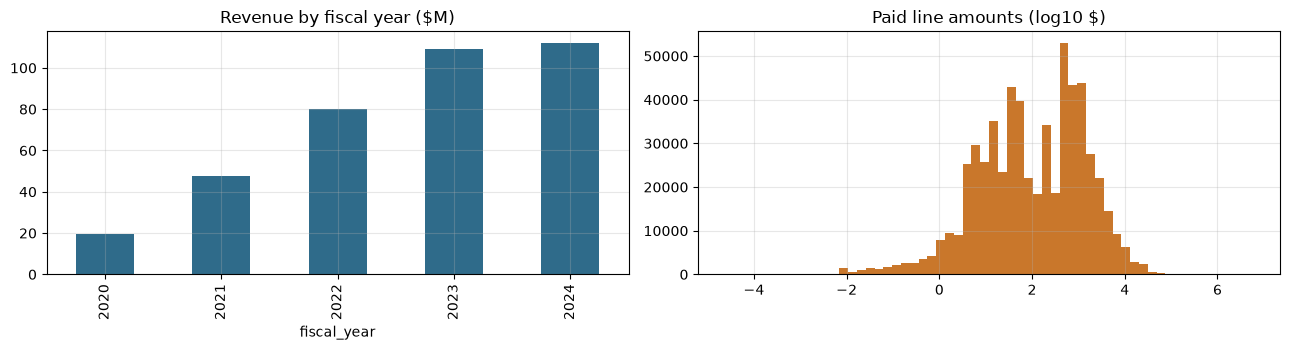

In [3]:
by_year = trial.groupby("fiscal_year").agg(revenue_M=("amount", lambda s: s.sum() / 1e6), lines=("amount", "size"),
                                           customers=("CustomerId", "nunique"), products=("CPPAppId", "nunique"))
by_year["revenue_growth"] = by_year.revenue_M.pct_change()
display(by_year)
zero = (trial.amount == 0).mean()
pair = trial.groupby(["CPPAppId", "CustomerId"]).amount.sum()
print(f"Billing lines at $0: {zero:.1%} | customer-product pairs that never paid: {(pair <= 0).mean():.1%}")
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
by_year.revenue_M.plot.bar(ax=ax[0], color=COLOR, title="Revenue by fiscal year ($M)")
ax[1].hist(np.log10(trial.amount[trial.amount > 0]), bins=60, color=ACCENT)
ax[1].set_title("Paid line amounts (log10 $)"); plt.tight_layout(); plt.show()

FY2020 has far fewer billing lines than the later years (98,000 against more than 230,000), so the jump from FY20 to
FY21 may partly reflect how much of that year the extract covers. Paid amounts range from cents to millions: averages are dominated by a few very large
lines, so medians and shares are used below.

### 2.2 Where the revenue comes from

In [4]:
def breakdown(col, data=trial):
    g = data.groupby(col)
    t = pd.DataFrame({"lines": g.size(), "revenue_M": g.amount.sum() / 1e6,
                      "paid_line_share": g.amount.apply(lambda s: (s > 0).mean()),
                      "median_paid_line": g.amount.apply(lambda s: s[s > 0].median())})
    t["revenue_share"] = t.revenue_M / t.revenue_M.sum()
    return t.sort_values("revenue_M", ascending=False)

for col in ["ServiceName", "ChannelName", "ActionName", "IsMACCEnrolledProduct"]:
    print(col); display(breakdown(col))

ServiceName


,lines,revenue_M,paid_line_share,median_paid_line,revenue_share
ServiceName,,,,,
Virtual Machine Licenses,1109815,270.07,0.46,207.45,0.73
SaaS,153026,97.17,0.46,14.99,0.26
Azure PowerBI Visual Service,18701,1.03,0.47,19.15,0.00
Dynamics 365 BC,668,0.12,0.40,19.79,0.00
Dynamics 365 CE,85,0.00,0.27,25.84,0.00


ChannelName


,lines,revenue_M,paid_line_share,median_paid_line,revenue_share
ChannelName,,,,,
Field-Led/EA,703821,257.36,0.39,509.64,0.70
Direct,371765,61.98,0.54,28.75,0.17
Partner-Led,143676,49.72,0.81,123.85,0.13


ActionName


,lines,revenue_M,paid_line_share,median_paid_line,revenue_share
ActionName,,,,,
consume,991894,269.68,0.52,207.16,0.73
purchase,175533,70.72,0.05,78.41,0.19
renew,114766,27.99,0.62,12.04,0.08
refund,102,-0.00,0.35,5.00,-0.00


IsMACCEnrolledProduct


,lines,revenue_M,paid_line_share,median_paid_line,revenue_share
IsMACCEnrolledProduct,,,,,
True,1091869,355.68,0.47,209.67,0.97
False,190426,12.70,0.42,14.22,0.03


In [5]:
paid = trial[trial.amount > 0]
tests = {}
for col in ["ServiceName", "ChannelName", "ActionName"]:
    groups = [g.amount.values for _, g in paid.dropna(subset=[col]).groupby(col) if len(g) > 30]
    tests[col] = stats.kruskal(*groups).pvalue
m = paid.groupby("IsMACCEnrolledProduct").amount
tests["IsMACCEnrolledProduct"] = stats.mannwhitneyu(m.get_group(True), m.get_group(False)).pvalue
print("Rank-based tests on paid line amounts (p-values):", {k: f"{v:.1e}" for k, v in tests.items()})
print("Median paid line, MACC enrolled vs not:", m.median().round(2).to_dict())

Rank-based tests on paid line amounts (p-values): {'ServiceName': '0.0e+00', 'ChannelName': '0.0e+00', 'ActionName': '0.0e+00', 'IsMACCEnrolledProduct': '0.0e+00'}
Median paid line, MACC enrolled vs not: {False: 14.22, True: 209.67}


With hundreds of thousands of paid lines, every difference is statistically significant; what matters is its size,
read from the tables above (revenue share and the median paid line per group).

### 2.3 Products, publishers, plans, refunds and customers

In [6]:
top_products = trial.groupby(["product", "PublisherName"]).amount.sum().sort_values(ascending=False).head(10) / 1e6
top_publishers = trial.groupby("PublisherName").amount.sum().sort_values(ascending=False).head(10) / 1e6
offers = trial.groupby("PublisherName").CPPAppId.nunique().sort_values(ascending=False).head(10)
plans = trial.groupby("TermDescription").amount.sum().sort_values(ascending=False).head(10) / 1e6
display(top_products.rename("revenue $M").to_frame()); display(top_publishers.rename("revenue $M").to_frame())
display(offers.rename("products offered").to_frame()); display(plans.rename("revenue $M").to_frame())
share = top_publishers.sum() / (trial.amount.sum() / 1e6)
print(f"The 10 largest publishers earn {share:.0%} of revenue")

,,revenue $M
product,PublisherName,
Fortinet FortiGate Next-Generation Firewall (VM),Fortinet,87.25
VM-Series Next Generation Firewall,"Palo Alto Networks, Inc.",40.28
Nasuni File Data Platform,Nasuni Corporation,26.26
F5 BIG-IP Virtual Edition - BEST (PAYG),F5 Networks,21.13
Azure Native Dynatrace Service,Dynatrace,19.81
NetApp Cloud Volumes ONTAP – Cloud Storage,NetApp,17.30
Barracuda CloudGen WAF for Azure,"Barracuda Networks, Inc.",14.91
Akamai Kona Site Defender plus Ion,Akamai Technologies,11.70
Cisco Cloud Services Router (CSR) 1000V,"Cisco Systems, Inc.",10.90


,revenue $M
PublisherName,
Fortinet,87.42
"Palo Alto Networks, Inc.",40.28
F5 Networks,35.47
Nasuni Corporation,26.26
"Barracuda Networks, Inc.",25.13
Dynatrace,19.81
NetApp,17.30
"Cisco Systems, Inc.",13.74
Akamai Technologies,12.56


,products offered
PublisherName,
PBIVizEdit.com,39
xViz LLC,17
cloudimg,16
NIC Systems Inc.,14
YASEEN'S MARKET LTD,12
The Global Solutions LLC,9
ISVTestUKLegacy,9
enclaive GmbH,8
TRUVIZ INC,7


,revenue $M
TermDescription,
1 Compute Hour,267.86
1 Year Subscription,69.40
1 Month Subscription,17.18
3 Years Subscription,8.83
2 Years Subscription,1.47
MongoDB Atlas Credits,1.10
3 Years 16core for reservation,0.85
3 Years 8core for reservation,0.77
Usage over the committed amount,0.22


The 10 largest publishers earn 78% of revenue


In [7]:
refunds = trial[trial.ActionName == "refund"]
print(f"Refund lines: {len(refunds)} for {refunds['product'].nunique()} products, total ${refunds.amount.sum():,.0f} "
      f"({-refunds.amount.sum() / trial.amount.sum():.2%} of revenue)")
display(refunds.groupby("product").amount.agg(["size", "sum"]).sort_values("sum").rename(columns={"size": "lines", "sum": "refunded $"}))
cust = trial.groupby("CustomerId").amount.sum().sort_values(ascending=False)
cum = cust.cumsum() / cust.sum()
for q in (0.01, 0.05, 0.20):
    print(f"Top {q:.0%} of customers bring {cum.iloc[int(len(cum) * q) - 1]:.0%} of revenue")
print(f"Customers who never paid anything: {(cust <= 0).mean():.0%}")

Refund lines: 102 for 5 products, total $-72 (0.00% of revenue)


,lines,refunded $
product,,
Pickit Business,69,-72.50
F5 BIG-IP Virtual Edition - BEST (PAYG),11,0.00
Fortinet FortiGate Next-Generation Firewall (VM),12,0.00
LawToolBox for Microsoft 365,8,0.00
ScrumGenius - Automate daily standups,2,0.00


Top 1% of customers bring 66% of revenue
Top 5% of customers bring 91% of revenue
Top 20% of customers bring 100% of revenue
Customers who never paid anything: 51%


### 2.4 Do ratings go with revenue?

203 of 939 products have a marketplace rating; 90% of those rate above 4
Spearman correlation of product revenue with rating    : -0.36 (p=1.7e-07, n=203)
Spearman correlation of product revenue with n_ratings : +0.32 (p=3.0e-23, n=939)


Spearman correlation of product revenue with customers : +0.64 (p=3.3e-110, n=939)


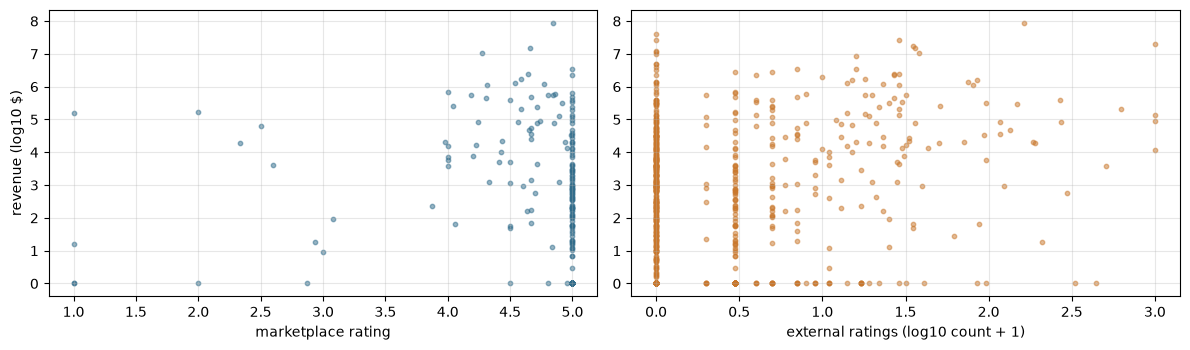

In [8]:
prod = trial.groupby("CPPAppId").agg(revenue=("amount", "sum"), rating=("StarRatingMarketplace", "mean"),
                                     n_ratings=("NumberOfRatingsExternal", "max"), customers=("CustomerId", "nunique"))
rated = prod.dropna(subset=["rating"])
print(f"{len(rated)} of {len(prod)} products have a marketplace rating; {(rated.rating > 4).mean():.0%} of those rate above 4")
for c in ["rating", "n_ratings", "customers"]:
    d = prod.dropna(subset=[c])
    rho, p = stats.spearmanr(d[c], d.revenue)
    print(f"Spearman correlation of product revenue with {c:10}: {rho:+.2f} (p={p:.1e}, n={len(d)})")
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].scatter(rated.rating, np.log10(rated.revenue.clip(lower=1)), s=10, alpha=.5, color=COLOR)
ax[0].set_xlabel("marketplace rating"); ax[0].set_ylabel("revenue (log10 $)")
ax[1].scatter(np.log10(prod.n_ratings + 1), np.log10(prod.revenue.clip(lower=1)), s=10, alpha=.5, color=ACCENT)
ax[1].set_xlabel("external ratings (log10 count + 1)"); plt.tight_layout(); plt.show()

Almost every rated product sits between 4 and 5 stars, and the higher-rated ones earn *less* (rank correlation
about -0.36): small products tend to have a few perfect ratings, large ones many mixed ratings. The number of ratings
and the number of customers move with revenue, as expected for popular products: they measure reach, not quality.

## 3. Products with free plans: who goes on to pay?

A customer converts on a product if they ever pay for it. Rates are compared per product, for products with at least
20 customers.

324,153 customer-product pairs; 31.5% paid
Products with at least 20 customers: 848 of 7265


,size,median,mean
free_trial,,,
False,651,0.38,0.42
True,197,0.43,0.44


Mann-Whitney p-value: 2.4e-01


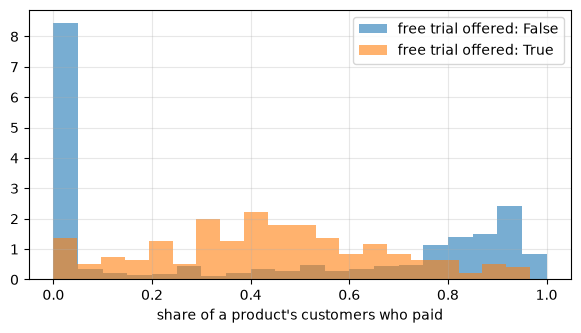

In [9]:
pairs = plan.groupby(["CPPAppId", "CustomerId"]).agg(paid=("amount", lambda s: s.sum() > 0),
                                                    trial=("HasFreeTrials", "first"))
print(f"{len(pairs):,} customer-product pairs; {pairs.paid.mean():.1%} paid")
per_product = pairs.groupby("CPPAppId").agg(customers=("paid", "size"), conversion=("paid", "mean"),
                                            free_trial=("trial", "first"))
big = per_product[per_product.customers >= 20]
print(f"Products with at least 20 customers: {len(big)} of {len(per_product)}")
cmp = big.groupby("free_trial").conversion.agg(["size", "median", "mean"])
display(cmp)
print("Mann-Whitney p-value:", f"{stats.mannwhitneyu(*[g.conversion for _, g in big.groupby('free_trial')]).pvalue:.1e}")
fig, ax = plt.subplots(figsize=(7, 3.5))
for t, g in big.groupby("free_trial"):
    ax.hist(g.conversion, bins=20, alpha=.6, label=f"free trial offered: {t}", density=True)
ax.set_xlabel("share of a product's customers who paid"); ax.legend(); plt.show()

In [10]:
names = plan.groupby("CPPAppId")["product"].first()
best = big.sort_values(["conversion", "customers"], ascending=False).head(10).join(names)
display(best[["product", "customers", "conversion", "free_trial"]])
terms = plan.groupby("TermDescription").agg(paying_customers=("CustomerId", lambda s: s[plan.loc[s.index, "amount"] > 0].nunique()),
                                            revenue_M=("amount", lambda s: s.sum() / 1e6))
display(terms.sort_values("revenue_M", ascending=False).head(8))

,product,customers,conversion,free_trial
CPPAppId,,,,
ppmworksinc1604096364482.pjpnsync,Project Planner Sync,29,1.00,False
bansirllc1619470302579.005-com-centos-server-7-9,CentOS Server 7.9,23,1.00,False
avi-networks.avi-vantage-adc,VMware NSX Advanced Load Balancer (Avi Networks),22,1.00,False
ntegralinc1586961136942.ntg_fedora_39,Fedora 39,22,1.00,False
amestofortytwoas1653635920536.self_hosted_runner_ado,Self Hosted Runner for Azure DevOps,20,1.00,False
f5-networks.f5_networks_direct_azure,F5 Inc. Solutions,52,0.98,False
ntegralinc1586961136942.ntg_amzn_linux_2023,Amazon Linux 2023,52,0.98,False
cloudwhizsolutions.docker-community-edition-with-ubuntu-1804-lts,docker On Ubuntu 18.04 LTS Bionic,44,0.98,False
cognosys.umbraco-with-windows-server-2019,Umbraco: The Flexible CMS for Windows server 2019 and AZURE,44,0.98,False


,paying_customers,revenue_M
TermDescription,,
1 Year Subscription,5365,579.61
1 Compute Hour,32834,265.06
3 Years Subscription,228,252.95
1 Month Subscription,33576,124.01
Elastic Billing Units for Azure,5837,74.08
Snowflake Usage,4,43.08
2 Years Subscription,99,41.94
MongoDB Atlas Credits,480,39.09


## 4. Trial funnels and the time to convert

In [11]:
funnel = pd.read_csv("data/trials/trial_time_hours.csv")
funnel = funnel.drop_duplicates()
funnel["days_to_convert"] = funnel.AvgTimeToConvert / 24
funnel["median_days"] = funnel.MedianTimeToConvert / 24
print(f"{len(funnel)} products with free plans and at least one conversion")
summary = funnel.groupby("HasFreeTrials").agg(products=("ProductDisplayName", "size"),
                                             trial_customers=("TrialCustomers", "sum"),
                                             converted=("ConvertedCustomers", "sum"),
                                             median_conversion=("TrialConversionRate", "median"),
                                             median_avg_days=("days_to_convert", "median"))
summary["pooled_conversion"] = summary.converted / summary.trial_customers
display(summary)

1089 products with free plans and at least one conversion


,products,trial_customers,converted,median_conversion,median_avg_days,pooled_conversion
HasFreeTrials,,,,,,
False,647,75107,20564,0.50,0.02,0.27
True,442,18463,6907,0.46,30.64,0.37


            products  median_conversion  median_avg_days  median_median_days
kind                                                                        
free plan        178               0.23            13.11                0.00
free trial       175               0.32            30.61               30.00


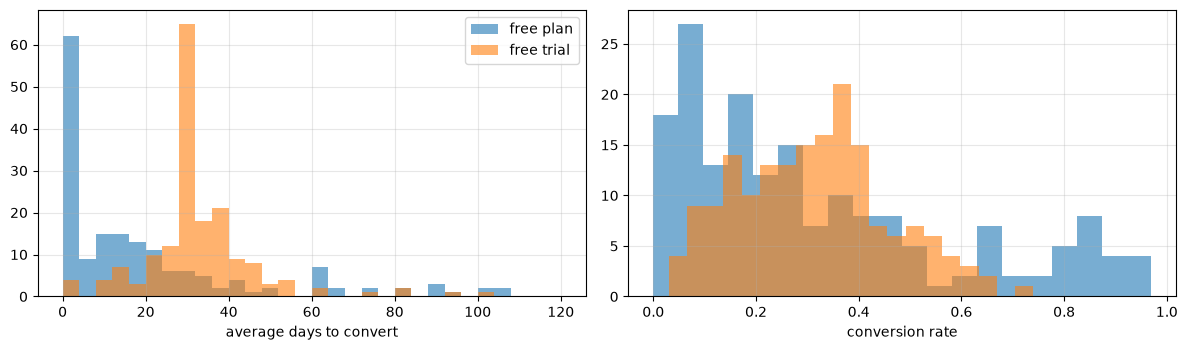

In [12]:
plan_days = pd.read_csv("data/trials/FreePlanDays.csv").assign(kind="free plan")
trial_days = pd.read_csv("data/trials/FreeTrialDays.csv").assign(kind="free trial")
days = pd.concat([plan_days, trial_days], ignore_index=True)
days = days[days.TrialCustomers >= 10]
print(days.groupby("kind").agg(products=("ProductDisplayName", "size"), median_conversion=("TrialConversionRate", "median"),
                               median_avg_days=("AvgDaysToConvert", "median"), median_median_days=("MedianDaysToConvert", "median")))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
for k, g in days.groupby("kind"):
    ax[0].hist(g.AvgDaysToConvert, bins=30, range=(0, 120), alpha=.6, label=k)
    ax[1].hist(g.TrialConversionRate, bins=20, alpha=.6, label=k)
ax[0].set_xlabel("average days to convert"); ax[1].set_xlabel("conversion rate"); ax[0].legend()
plt.tight_layout(); plt.show()

In [13]:
top_conv = pd.concat([pd.read_csv("data/trials/Free plans, Top 10 converted, Trialssss.csv").assign(kind="free plan"),
                      pd.read_csv("data/trials/FreeTrials, Top 10 converted, Trial.csv").assign(kind="free trial")])
for k, g in top_conv.groupby("kind"):
    print(f"Most converted customers, {k} products:")
    display(g.sort_values("ConvertedCustomers", ascending=False).head(10)[["ProductDisplayName", "PublisherName",
                                                                          "TrialCustomers", "ConvertedCustomers",
                                                                          "TrialConversionRate"]])

Most converted customers, free plan products:

,ProductDisplayName,PublisherName,TrialCustomers,ConvertedCustomers,TrialConversionRate
0,Twilio SendGrid,SendGrid,"40,194.00","7,957.00",0.20
1,Elastic Search (Elasticsearch) – An Azure Native ISV Ser...,Elastic,"5,799.00","3,508.00",0.60
10,MongoDB Atlas (pay-as-you-go),"MongoDB, Inc.","2,042.00","1,019.00",0.50
14,Nerdio Manager for MSP,Nerdio,"1,545.00",849.00,0.55
17,Azure Cache for Redis Enterprise & Flash,Redis,827.00,699.00,0.85
19,Billing subscription to Nerdio Manager for Enterprise,Nerdio,751.00,696.00,0.93
15,Apache Kafka® & Apache Flink® on Confluent Cloud™ - An A...,Confluent,"1,248.00",576.00,0.46
18,InfluxDB Cloud (Official Version),InfluxData Inc.,826.00,356.00,0.43
34,NGINX as a Service – Azure Native ISV Service,"F5, Inc.",428.00,340.00,0.79
20,NetApp BlueXP,NetApp,714.00,304.00,0.43


Most converted customers, free trial products:


,ProductDisplayName,PublisherName,TrialCustomers,ConvertedCustomers,TrialConversionRate
1,Fortinet FortiGate Next-Generation Firewall (VM),Fortinet,"2,135.00","1,154.00",0.54
0,Ubuntu Pro 18.04 LTS,Canonical,"3,429.00",857.00,0.25
3,VM-Series Next Generation Firewall,"Palo Alto Networks, Inc.",759.00,428.00,0.56
2,Ubuntu Pro 22.04 LTS,Canonical,915.00,386.00,0.42
6,Inforiver Premium Matrix / Table,xViz LLC,444.00,279.00,0.63
4,Ubuntu Pro 20.04 LTS,Canonical,514.00,273.00,0.53
8,CyberGate SIP intercom connect to Teams,CyberTwice B.V.,325.00,228.00,0.70
5,"Plesk on Linux - WordPress, Website and Web hosting Plat...",Plesk,462.00,224.00,0.48
9,SFTP Gateway for Azure - SFTP to Blob storage,Thorn Technologies LLC,313.00,199.00,0.64
11,Financial Reporting Matrix by Profitbase,Profitbase AS,279.00,165.00,0.59


Free plans convert almost immediately or not at all: the typical product's median time to pay is zero days, because
customers who intend to pay often do so on the first day. Free trials convert later, around the end of the trial
month (about 30 days), which is exactly when a reminder or an offer can help.

### 4.1 Ratings and conversion

In [14]:
ratings = pd.read_csv("data/trials/Ratings.csv").drop_duplicates()
ratings["has_rating"] = ratings.AvgStarRatingExternal.notna() | ratings.AvgStarRatingMarketplace.notna()
r = ratings.dropna(subset=["TrialConversionRate"])
r = r[r.TrialCustomers >= 10]
print(f"{len(r)} products with at least 10 trial customers")
display(r.groupby("has_rating").agg(products=("CPPAppId", "size"), median_conversion=("TrialConversionRate", "median"),
                                   median_revenue=("TotalRevenue", "median")))
rr = r.dropna(subset=["AvgStarRatingExternal"])
rho, p = stats.spearmanr(rr.AvgStarRatingExternal, rr.TrialConversionRate)
print(f"Spearman correlation of external rating with conversion: {rho:+.2f} (p={p:.2f}, n={len(rr)})")

950 products with at least 10 trial customers


,products,median_conversion,median_revenue
has_rating,,,
False,598,0.04,75.63
True,352,0.30,"10,660.11"


Spearman correlation of external rating with conversion: +0.00 (p=0.98, n=352)


## 5. Customer segments and channels

In [15]:
seg = pd.read_excel("data/trials/SMB.xlsx").dropna().drop_duplicates("Customer ID")
seg.columns = ["CustomerId", "segment"]
cust_trial = trial.groupby("CustomerId").agg(revenue=("amount", "sum")).join(seg.set_index("CustomerId"))
print(f"Trial-product customers with a known segment: {cust_trial.segment.notna().mean():.0%}")
known = cust_trial.dropna(subset=["segment"])
t = known.groupby("segment").agg(customers=("revenue", "size"), paying_share=("revenue", lambda s: (s > 0).mean()),
                                 revenue_M=("revenue", lambda s: s.sum() / 1e6),
                                 median_paying_customer=("revenue", lambda s: s[s > 0].median()))
t["revenue_share"] = t.revenue_M / t.revenue_M.sum()
t["never_paid"] = 1 - t.paying_share
display(t.sort_values("revenue_M", ascending=False))

Trial-product customers with a known segment: 68%


,customers,paying_share,revenue_M,median_paying_customer,revenue_share,never_paid
segment,,,,,,
Enterprise,6043,0.82,271.06,"2,294.32",0.74,0.18
SMB,24547,0.70,68.06,100.00,0.18,0.30
SMC-C,2662,0.74,29.26,"1,004.09",0.08,0.26


Free-trial products, by segment and channel:


,SummarySegment,ChannelName,TotalTrialCustomers,TotalConvertedCustomers,TotalRevenue,TrialConversionRate
0,Enterprise,Partner-Led,242.00,171.00,"2,218,118.60",0.71
1,SMC-C,Partner-Led,183.00,123.00,"1,845,365.76",0.67
2,Enterprise,Field-Led/EA,"2,715.00","1,737.00","71,320,402.40",0.64
3,SMB,Partner-Led,"1,411.00",878.00,"5,295,542.30",0.62
4,SMC-C,Field-Led/EA,376.00,228.00,"1,182,894.24",0.61
5,SMB,Direct,"7,253.00","4,344.00","3,602,150.81",0.60
6,SMB,Field-Led/EA,319.00,184.00,"1,918,069.51",0.58
7,SMC-C,Direct,487.00,240.00,"979,150.40",0.49
8,Enterprise,Direct,723.00,259.00,"1,677,721.57",0.36


Free-plan products, by segment and channel:


,SummarySegment,ChannelName,TotalTrialCustomers,TotalConvertedCustomers,TotalRevenue,TrialConversionRate
0,Enterprise,Field-Led/EA,13752,6025,"687,096,859.98",0.44
1,SMB,Direct,23615,10246,"26,731,576.55",0.43
2,SMC-C,Field-Led/EA,2302,967,"12,918,652.54",0.42
3,SMB,Field-Led/EA,1948,812,"10,016,943.16",0.42
4,SMC-C,Direct,1838,729,"19,914,680.76",0.40
5,SMB,Partner-Led,6559,2374,"11,277,193.67",0.36
6,Enterprise,Direct,2960,1063,"23,864,257.14",0.36
7,SMC-C,Partner-Led,731,253,"2,575,949.77",0.35
8,Enterprise,Partner-Led,926,319,"2,966,872.06",0.34
9,unknown,Partner-Led,393,16,"14,734.48",0.04


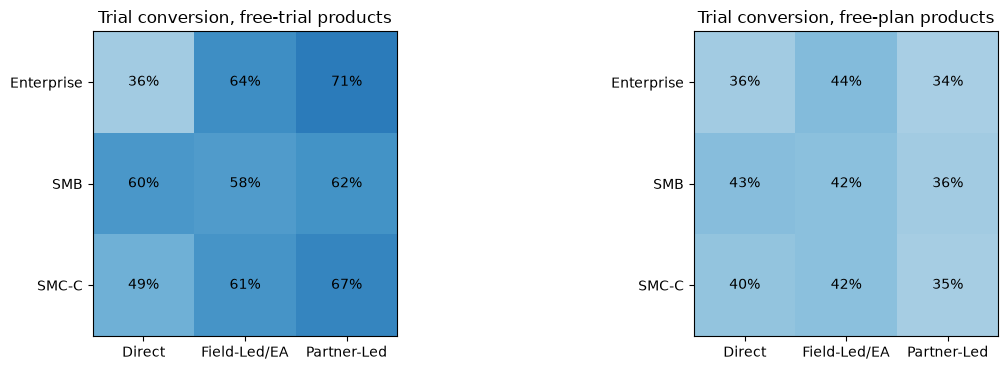

In [16]:
sc = pd.read_csv("data/trials/Summary Segment   Channel Name.csv").dropna()
sc.columns = [c.strip() for c in sc.columns]
sc["TotalRevenue"] = money(sc.TotalRevenue)
pf = pd.read_csv("data/trials/Summary Segment Channel Name Free Plan.csv")
pf.columns = [c.strip() for c in pf.columns]
for c in pf.columns:
    if not pd.api.types.is_numeric_dtype(pf[c]) and pf[c].astype(str).str.contains(r"\$").any():
        pf[c] = money(pf[c])
pf = pf[pf.ChannelName.notna() & (pd.to_numeric(pf.TotalTrialCustomers, errors="coerce") > 0)]
pf = pf[~pf.SummarySegment.isin(["SummarySegment", "Grand Total"])].copy()
pf["SummarySegment"] = pf.SummarySegment.fillna("unknown")
for c in ["TotalTrialCustomers", "TotalConvertedCustomers", "TotalRevenue", "TrialConversionRate"]:
    pf[c] = pd.to_numeric(pf[c], errors="coerce")
print("Free-trial products, by segment and channel:"); display(sc)
print("Free-plan products, by segment and channel:"); display(pf)
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for a, d, title in [(ax[0], sc, "free-trial products"), (ax[1], pf[pf.SummarySegment != "unknown"], "free-plan products")]:
    pv = d.pivot_table(index="SummarySegment", columns="ChannelName", values="TrialConversionRate")
    im = a.imshow(pv.values, cmap="Blues", vmin=0, vmax=1)
    a.set_xticks(range(len(pv.columns)), pv.columns); a.set_yticks(range(len(pv.index)), pv.index); a.grid(False)
    for i in range(pv.shape[0]):
        for j in range(pv.shape[1]):
            a.text(j, i, f"{pv.values[i, j]:.0%}" if pd.notna(pv.values[i, j]) else "", ha="center", va="center")
    a.set_title(f"Trial conversion, {title}")
plt.tight_layout(); plt.show()

In [17]:
ch = sc.groupby("ChannelName")[["TotalTrialCustomers", "TotalConvertedCustomers", "TotalRevenue"]].sum()
ch["conversion"] = ch.TotalConvertedCustomers / ch.TotalTrialCustomers
ch["revenue_share"] = ch.TotalRevenue / ch.TotalRevenue.sum()
ch["revenue_per_converted"] = ch.TotalRevenue / ch.TotalConvertedCustomers
ch

,TotalTrialCustomers,TotalConvertedCustomers,TotalRevenue,conversion,revenue_share,revenue_per_converted
ChannelName,,,,,,
Direct,"8,463.00","4,843.00","6,259,022.78",0.57,0.07,"1,292.39"
Field-Led/EA,"3,410.00","2,149.00","74,421,366.15",0.63,0.83,"34,630.70"
Partner-Led,"1,836.00","1,172.00","9,359,026.66",0.64,0.10,"7,985.52"


## 6. Conclusions and recommendations

- **Growth is slowing.** Revenue from free-trial products more than doubled from FY21 to FY23 but rose only 3% in FY24, while the number of products kept growing (574 to 754): more offers are sharing a similar total.
- **A few products, publishers and customers carry the marketplace.** Virtual-machine licences (73% of revenue), field-led enterprise sales (70%), MACC-enrolled products (97%), the top ten publishers (78%) and the top 1% of customers (66%). Most results move with a handful of large security and infrastructure products (Fortinet, Palo Alto Networks, F5, Nasuni).
- **Refunds are negligible**: 102 refund lines for five products, $72 in total.
- **Free trial or free plan, the decisive moment differs.** A free-plan customer who will pay usually does so on day one; a free-trial customer pays around day 30. Publishers with trials should act in the last week of the trial (reminders, onboarding help, an offer); publishers with free plans should make the first session count.
- **Adding a free trial to a free-plan product does not raise conversion** (median 43% against 38% for products with 20+ customers, not significant). The offer type matters less than the product.
- **Ratings: having them matters, the score does not.** Rated products convert far more often (median 30% against 4%), but among rated products the star rating is unrelated to conversion (correlation 0.00). Getting the first reviews is worth more than polishing the score.
- **Enterprise customers are few and decisive.** 18% of segmented customers, 74% of revenue, 82% of them pay, with a median of about $2,300 per paying customer against $100 for SMB. Field-led sales convert 63% of trials and bring $34,600 per converted customer, 27 times the Direct channel.
- **Customers without a known segment almost never pay**: 1.4% of 36,219 Direct free-plan customers converted, against 34% to 44% for every known segment. Identifying who these customers are is the first step before spending on them.

**Limits.** Billing extracts without dates within a fiscal year; the free-plan files cover months unevenly; customer
segments are known for about two thirds of trial-product customers and under half of free-plan customers; ratings
exist for a minority of products. The analysis describes what happened in the marketplace, not why.